# Statistics: off-contract timing, contract growth, expiry risk

Phase 3b of the vendor spend & contract compliance case study. Reads the marts in schema `dw` (build them with `python -m src.model.build_model`). Snapshot date: see `ref.run_params`.

Three questions:

1. **When does off-contract purchasing happen?** The plan asked about departments, but direct vouchers carry no department, so this tests timing instead.
2. **Do contracts grow more after award depending on how they were procured?** Sole source vs. competitive; RFP vs. bid.
3. **How much spend is at risk on contracts expiring in the next 90 days?**

All data are observational: these tests describe associations, not causes.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.contingency_tables import Table2x2

import sys; sys.path.insert(0, '..')
from src.db import connect

warnings.filterwarnings('ignore', category=UserWarning)

def q(sql, params=None):
    with connect() as conn:
        cur = conn.execute(sql, params)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

# Chart styling: one axis, recessive grid, text in ink colors (not series colors).
BLUE, ORANGE = '#2a78d6', '#eb6834'          # categorical slots 1 and 2
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'text.color': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 10, 'lines.linewidth': 2,
})

as_of = q('select as_of_date from ref.run_params').as_of_date[0]
print('Snapshot date:', as_of)

Snapshot date: 2026-10-31


## 1. When does off-contract purchasing happen?

**Scope:** purchasing payments (contract payments + purchasing-type direct vouchers) from Jan 2025, the first month both are itemized, through Sep 2026 (the last full month).

**Hypothesis going in:** a December (fiscal year-end) spike.

**History.** The first run of this notebook (before Phase 4) found no December spike but a January–February rise in off-contract *dollars*, and traced it to annual insurance renewals paid through brokers (Test 1d). The Phase 4 review then judged those broker payments to be premium pass-throughs, not purchasing, and insurance was reclassified. The charts and tests below use the current classification; Test 1d keeps the insurance evidence.

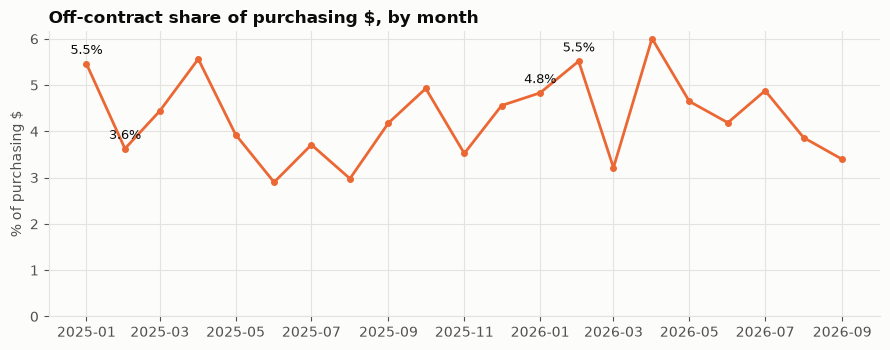

,month,dv_n,contract_n,off_contract_share
0,2025-01-01,2209,6946,0.055
1,2025-02-01,1702,6846,0.036
2,2025-03-01,2991,6079,0.044
3,2025-04-01,1899,5127,0.056
4,2025-05-01,2010,5211,0.039
5,2025-06-01,1964,5169,0.029
6,2025-07-01,1934,6463,0.037
7,2025-08-01,2153,6145,0.030
8,2025-09-01,2074,5721,0.042
9,2025-10-01,1974,5206,0.049


In [2]:
monthly = q('''
    select date_trunc('month', payment_date)::date as month,
           count(*) filter (where is_direct_voucher)          as dv_n,
           count(*) filter (where not is_direct_voucher)      as contract_n,
           sum(amount) filter (where is_direct_voucher)       as dv_usd,
           sum(amount)                                         as total_usd
    from dw.mart_payment_exceptions
    where payment_date >= '2025-01-01' and payment_date < '2026-10-01'
    group by 1 order by 1''')
monthly['month'] = pd.to_datetime(monthly.month)
for c in ['dv_usd', 'total_usd']:
    monthly[c] = monthly[c].astype(float)
monthly['off_contract_share'] = monthly.dv_usd / monthly.total_usd
monthly['jan_feb'] = monthly.month.dt.month.isin([1, 2])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(monthly.month, monthly.off_contract_share * 100, color=ORANGE, marker='o', markersize=4)
for _, r in monthly[monthly.jan_feb].iterrows():
    ax.annotate(f"{r.off_contract_share:.1%}", (r.month, r.off_contract_share * 100),
                textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9, color=INK)
ax.set_title('Off-contract share of purchasing $, by month')
ax.set_ylabel('% of purchasing $')
ax.set_ylim(0, None)
plt.tight_layout(); plt.show()

monthly.assign(off_contract_share=monthly.off_contract_share.round(3))[['month', 'dv_n', 'contract_n', 'off_contract_share']]

**Test 1a: does the off-contract mix vary by calendar month?** Chi-square test of independence on payment counts (month × off-contract vs. contract). With ~170k payments almost any difference is "significant", so the effect size (Cramér's V) is what matters.

In [3]:
table = monthly.assign(m=monthly.month.dt.month).groupby('m')[['dv_n', 'contract_n']].sum()
chi2, p, dof, _ = stats.chi2_contingency(table.values)
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f'chi2 = {chi2:,.0f}, dof = {dof}, p = {p:.2g}, n = {n:,}')
print(f"Cramer's V = {cramers_v:.3f}  (0.1 = small, 0.3 = medium)")

chi2 = 465, dof = 11, p = 7.3e-93, n = 164,075
Cramer's V = 0.053  (0.1 = small, 0.3 = medium)


**Test 1b: are January–February payments more likely to be off-contract than the rest of the year?** A 2×2 table (Jan–Feb vs. other months × off-contract vs. contract), reported as an odds ratio with a 95% confidence interval. Dollar shares are reported alongside, since counts and dollars can disagree.

In [4]:
jf = monthly.groupby('jan_feb')[['dv_n', 'contract_n', 'dv_usd', 'total_usd']].sum()
t = Table2x2(np.array([[jf.loc[True, 'dv_n'], jf.loc[True, 'contract_n']],
                       [jf.loc[False, 'dv_n'], jf.loc[False, 'contract_n']]]))
lo, hi = t.oddsratio_confint()
print(f'Odds ratio (Jan-Feb vs other months) = {t.oddsratio:.2f}  95% CI [{lo:.2f}, {hi:.2f}]  p = {t.oddsratio_pvalue():.2g}')
print(f"Off-contract share of $: Jan-Feb {jf.loc[True,'dv_usd']/jf.loc[True,'total_usd']:.1%}  vs  "
      f"other months {jf.loc[False,'dv_usd']/jf.loc[False,'total_usd']:.1%}")

Odds ratio (Jan-Feb vs other months) = 0.81  95% CI [0.79, 0.83]  p = 5.8e-51
Off-contract share of $: Jan-Feb 4.8%  vs  other months 4.2%


**Test 1c: is the Jan–Feb rise a bridge for lapsed contracts?** If agreements end Dec 31 and renewals take weeks, early-year direct vouchers should go disproportionately to vendors whose contract **ended in the previous 90 days**.

In [5]:
bridge = q('''
    select extract(month from e.payment_date) in (1, 2)          as jan_feb,
           exists (select 1 from dw.dim_contract c
                   where c.vendor_key = e.vendor_key
                     and c.current_end_date between e.payment_date - 90 and e.payment_date - 1
           )                                                    as vendor_contract_recently_ended,
           count(*) as payments, sum(e.amount) as usd
    from dw.mart_payment_exceptions e
    where e.is_direct_voucher and e.payment_date >= '2025-01-01' and e.payment_date < '2026-10-01'
    group by 1, 2''')
bridge['usd'] = bridge.usd.astype(float)
pivot = bridge.pivot_table(index='jan_feb', columns='vendor_contract_recently_ended', values=['payments', 'usd'], aggfunc='sum')
share_usd = pivot['usd'][True] / pivot['usd'].sum(axis=1)
print('Share of off-contract $ paid to vendors whose contract ended in the prior 90 days:')
print(f'  Jan-Feb:       {share_usd[True]:.1%}')
print(f'  other months:  {share_usd[False]:.1%}')

t2 = Table2x2(np.array([[pivot['payments'].loc[True, True], pivot['payments'].loc[True, False]],
                        [pivot['payments'].loc[False, True], pivot['payments'].loc[False, False]]]))
lo, hi = t2.oddsratio_confint()
print(f'Odds ratio (payment count) = {t2.oddsratio:.2f}  95% CI [{lo:.2f}, {hi:.2f}]  p = {t2.oddsratio_pvalue():.2g}')

Share of off-contract $ paid to vendors whose contract ended in the prior 90 days:
  Jan-Feb:       6.8%
  other months:  4.1%
Odds ratio (payment count) = 1.22  95% CI [1.04, 1.45]  p = 0.017


**Test 1d: what made January–February dollars higher under the original classification?** Insurance direct vouchers (now classified as premium pass-throughs) by month. Under an even spread, Jan–Feb would hold about 4/21 ≈ 19% of a type's dollars.

In [6]:
ins = q('''
    select payee_type,
           sum(amount) filter (where extract(month from payment_date) in (1, 2)) as jan_feb_usd,
           sum(amount)                                                         as total_usd
    from dw.fact_payment
    where is_direct_voucher and payee_type in ('insurance_risk', 'goods_services', 'outside_counsel')
      and payment_date >= '2025-01-01' and payment_date < '2026-10-01'
    group by 1''').set_index('payee_type').astype(float)
ins['share_in_jan_feb'] = ins.jan_feb_usd / ins.total_usd
print(f'Expected share under an even spread: {4/21:.0%}')
print(ins.assign(jan_feb_usd=lambda d: (d.jan_feb_usd/1e6).round(1), total_usd=lambda d: (d.total_usd/1e6).round(1),
                 share_in_jan_feb=lambda d: d.share_in_jan_feb.round(3)))

Expected share under an even spread: 19%
                 jan_feb_usd  total_usd  share_in_jan_feb
payee_type                                               
goods_services          68.1      336.1             0.203
insurance_risk          61.7      126.2             0.489
outside_counsel         33.5      124.3             0.270


**Result.** About half of insurance direct-voucher dollars are paid in January–February: annual premium renewals through brokers (largest: USI Insurance Services, 87% of its dollars in $1M+ payments). Counted as purchasing, they produced the early-year rise; reclassified as pass-throughs (Phase 4), the remaining off-contract purchasing is spread close to evenly through the year.

## 2. Does contract growth differ by procurement method?

**Growth** = cumulative award ÷ original award. **Scope:** standard-procurement contracts paid since 2022, with a positive original award and a complete revision history (no missing revision numbers, which would understate growth).

Growth is heavily skewed (most contracts never change; a few grow many times over), so the tests are **Mann-Whitney U** (rank-based) with the **rank-biserial correlation** as effect size, plus a Fisher exact test on the share of contracts that grew at all.

In [7]:
growth = q('''
    select procurement_type, award_growth_ratio::float as growth
    from dw.mart_contract_spend
    where procurement_channel = 'Standard procurement'
      and original_award > 0 and has_complete_revision_history
      and award_growth_ratio is not null''')
growth['group'] = np.select(
    [growth.procurement_type == 'SOLE SOURCE', growth.procurement_type.isin(['BID', 'RFP', 'RFQ'])],
    ['Sole source', 'Competitive (bid / RFP / RFQ)'], 'Other')
growth['grew'] = growth.growth > 1.0001

summary = growth.groupby('procurement_type').agg(
    contracts=('growth', 'size'), median_growth=('growth', 'median'),
    share_grew=('grew', 'mean'), p90_growth=('growth', lambda s: s.quantile(0.9)))
summary.loc[['BID', 'RFP', 'RFQ', 'SOLE SOURCE']].round(2)

,contracts,median_growth,share_grew,p90_growth
procurement_type,,,,
BID,524,1.00,0.35,2.27
RFP,134,1.16,0.55,2.97
RFQ,88,1.00,0.32,1.77
SOLE SOURCE,51,1.00,0.35,5.26


In [8]:
def compare(a, b, label_a, label_b):
    u, p = stats.mannwhitneyu(a.growth, b.growth, alternative='two-sided')
    rbc = 1 - 2 * u / (len(a) * len(b))          # rank-biserial: >0 means a ranks lower than b
    grew = [[a.grew.sum(), (~a.grew).sum()], [b.grew.sum(), (~b.grew).sum()]]
    odds, p_f = stats.fisher_exact(grew)
    print(f'{label_a} (n={len(a)}) vs {label_b} (n={len(b)})')
    print(f'  median growth {a.growth.median():.2f}x vs {b.growth.median():.2f}x;  '
          f'grew at all {a.grew.mean():.0%} vs {b.grew.mean():.0%}')
    print(f'  Mann-Whitney U = {u:,.0f}, p = {p:.3g}, rank-biserial r = {-rbc:+.2f}  (|r| 0.1 small, 0.3 medium, 0.5 large)')
    print(f'  Fisher exact on "grew at all": odds ratio = {odds:.2f}, p = {p_f:.3g}\n')

compare(growth[growth.group == 'Sole source'], growth[growth.group.str.startswith('Competitive')],
        'Sole source', 'Competitive')
compare(growth[growth.procurement_type == 'RFP'], growth[growth.procurement_type == 'BID'], 'RFP', 'Bid')

Sole source (n=51) vs Competitive (n=746)
  median growth 1.00x vs 1.00x;  grew at all 35% vs 39%
  Mann-Whitney U = 20,258, p = 0.381, rank-biserial r = +0.06  (|r| 0.1 small, 0.3 medium, 0.5 large)
  Fisher exact on "grew at all": odds ratio = 0.87, p = 0.766

RFP (n=134) vs Bid (n=524)
  median growth 1.16x vs 1.00x;  grew at all 55% vs 35%
  Mann-Whitney U = 43,700, p = 1.02e-06, rank-biserial r = +0.24  (|r| 0.1 small, 0.3 medium, 0.5 large)
  Fisher exact on "grew at all": odds ratio = 2.24, p = 4.44e-05



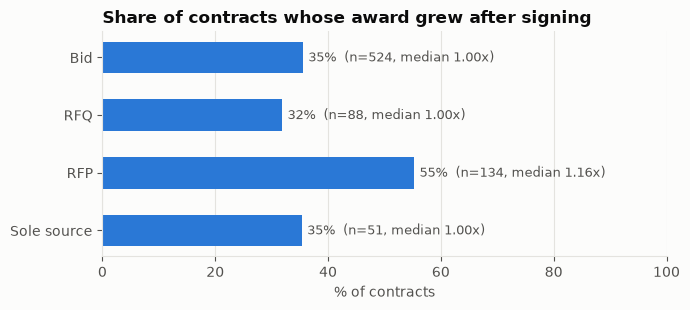

In [9]:
order = ['BID', 'RFQ', 'RFP', 'SOLE SOURCE']
s = summary.loc[order]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.set_axisbelow(True)
bars = ax.barh(['Bid', 'RFQ', 'RFP', 'Sole source'], s.share_grew * 100, color=BLUE, height=0.55)
for b, (_, r) in zip(bars, s.iterrows()):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2,
            f"{r.share_grew:.0%}  (n={int(r.contracts)}, median {r.median_growth:.2f}x)",
            va='center', fontsize=9, color=INK_2)
ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_title('Share of contracts whose award grew after signing')
ax.set_xlabel('% of contracts'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## 3. Spend at risk on contracts expiring in the next 90 days

**Scope:** the standard-procurement contracts with an end date within 90 days of the snapshot and payments in the last 12 months (`is_expiring_with_spend`). Grants and comptroller agreements on Dec 31 cycles are excluded (Phase 3).

**Run-rate** = average monthly spend over the last 6 full months (Apr–Sep 2026). **Trend** = OLS slope of monthly spend over the last 12 full months, to show whether spend is still rising. **6-month exposure** = run-rate × 6: what keeps flowing if the contract lapses before a replacement is in place.

In [10]:
exp = q('''
    with m as (
        select f.contract_number, date_trunc('month', f.payment_date)::date as month, sum(f.amount) as usd
        from dw.fact_payment f
        join dw.mart_contract_spend s using (contract_number)
        where s.is_expiring_with_spend and s.procurement_channel = 'Standard procurement'
          and f.payment_date >= '2025-10-01' and f.payment_date < '2026-10-01'
        group by 1, 2)
    select s.contract_number, s.vendor_name, s.category, s.current_end_date, s.days_to_expiry,
           s.paid_trailing_12m::float as paid_12m, m.month, coalesce(m.usd, 0)::float as usd
    from dw.mart_contract_spend s
    left join m using (contract_number)
    where s.is_expiring_with_spend and s.procurement_channel = 'Standard procurement' ''')

months = pd.date_range('2025-10-01', '2026-09-01', freq='MS')
grid = (exp.dropna(subset=['month']).assign(month=lambda d: pd.to_datetime(d.month))
          .pivot_table(index='contract_number', columns='month', values='usd', aggfunc='sum')
          .reindex(columns=months, fill_value=0).fillna(0))
x = np.arange(len(months))
slope = grid.apply(lambda r: np.polyfit(x, r.values, 1)[0], axis=1)
risk = (exp.drop_duplicates('contract_number').set_index('contract_number')
          [['vendor_name', 'category', 'current_end_date', 'days_to_expiry', 'paid_12m']]
          .join(grid.iloc[:, -6:].mean(axis=1).rename('run_rate_monthly'))
          .join(slope.rename('trend_per_month')).fillna({'run_rate_monthly': 0, 'trend_per_month': 0}))
risk['exposure_6m'] = risk.run_rate_monthly * 6
risk = risk.sort_values('exposure_6m', ascending=False)

print(f'{len(risk)} contracts; 6-month exposure ${risk.exposure_6m.sum()/1e6:,.1f}M; '
      f'top 10 = {risk.exposure_6m.head(10).sum()/risk.exposure_6m.sum():.0%} of it; '
      f'{(risk.trend_per_month > 0).sum()} with rising monthly spend')
risk.head(10).assign(paid_12m=lambda d: (d.paid_12m/1e6).round(1),
                     run_rate_monthly=lambda d: (d.run_rate_monthly/1e6).round(2),
                     trend_per_month=lambda d: (d.trend_per_month/1e3).round(0),
                     exposure_6m=lambda d: (d.exposure_6m/1e6).round(1)) \
    .rename(columns={'paid_12m': 'paid_12m_$M', 'run_rate_monthly': 'run_rate_$M',
                     'trend_per_month': 'trend_$K/mo', 'exposure_6m': 'exposure_6m_$M'})

83 contracts; 6-month exposure $126.1M; top 10 = 68% of it; 41 with rising monthly spend


,vendor_name,category,current_end_date,days_to_expiry,paid_12m_$M,run_rate_$M,trend_$K/mo,exposure_6m_$M
contract_number,,,,,,,,
25743,AOR TRANSIT,Professional services,2026-11-30,30,34.6,2.76,-652.0,16.6
247181,ALLIED WASTE TRANSPORTATION INC,Work services & maintenance,2026-10-31,0,27.6,2.35,28.0,14.1
110168,ALLIED WASTE TRANSPORTATION INC,Work services & maintenance,2026-12-31,61,28.1,2.01,-27.0,12.0
174908,STANDARD PARKING CORPORATION.,Professional services,2026-12-31,61,29.5,1.80,-366.0,10.8
91165,OZINGA READY MIX CONCRETE INC,Commodities,2027-01-06,67,17.0,1.53,66.0,9.2
102520,"ROSSI CONTRACTORS, INC.",Work services & maintenance,2026-12-07,37,20.8,1.02,-142.0,6.1
22875,CARE PLUS LLC|CLEANED-UP,Professional services,2026-12-31,61,8.4,0.76,-38.0,4.5
167483,"ELGIN SWEEPING SERVICES, INC.",Work services & maintenance,2026-12-31,61,6.7,0.69,28.0,4.2
167481,"CHRISTOFANO EQUIPMENT CO., INC.",Work services & maintenance,2026-12-31,61,7.7,0.66,-32.0,3.9


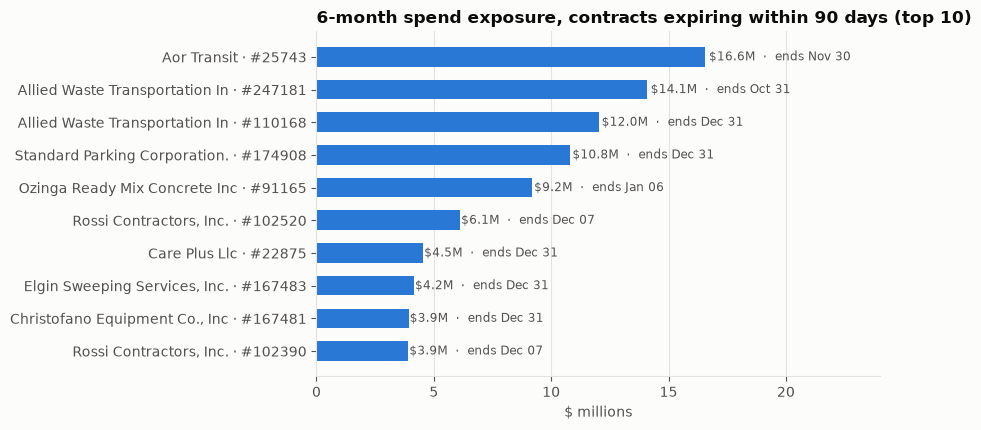

In [11]:
top = risk.head(10).iloc[::-1]
# Some vendors hold two expiring contracts, so label by vendor + contract number.
labels = [f"{v.split('|')[0][:30].title()} · #{c}" for c, v in zip(top.index, top.vendor_name)]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.set_axisbelow(True)
bars = ax.barh(labels, top.exposure_6m / 1e6, color=BLUE, height=0.6)
for b, (_, r) in zip(bars, top.iterrows()):
    ax.text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2,
            f"${r.exposure_6m/1e6:,.1f}M  ·  ends {r.current_end_date:%b %d}", va='center', fontsize=8.5, color=INK_2)
ax.set_title('6-month spend exposure, contracts expiring within 90 days (top 10)')
ax.set_xlabel('$ millions'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, top.exposure_6m.max() / 1e6 * 1.45)
plt.tight_layout(); plt.show()

## Results in plain language

1. **Off-contract purchasing has no year-end spike, and almost no seasonality.** Under the original classification January–February looked high (7.6% vs 5.0% of purchasing dollars), but that was annual insurance renewals paid through brokers, which Phase 4 reclassified as premium pass-throughs. Without them, Jan–Feb is 4.8% vs 4.2% for the rest of the year, and by payment count it is slightly *less* off-contract (odds ratio 0.81). Early-year off-contract dollars go somewhat more often to vendors whose contract just ended (6.8% vs 4.1%; OR 1.22 by count), a small renewal-gap effect.
2. **Contracts awarded by RFP grow after award more often than bid contracts**: 55% vs 35% grew, median 1.16× vs 1.00× (Mann-Whitney p ≈ 1e-6; rank-biserial r = 0.24, a small-to-medium effect). Plausibly because RFPs buy services whose scope evolves, while bids buy defined quantities. Sole-source contracts grow no differently from competitive ones (p = 0.38).
3. **Expiring contracts:** the 83 standard-procurement contracts ending within 90 days are spending about **$126M per 6 months**; ten contracts hold two-thirds of it, and half show rising monthly spend. These are the renewals procurement should have in motion now.

## Caveats

- **Observational data.** The tests show associations. A Jan–Feb rise in off-contract spend that coincides with Dec 31 contract endings is consistent with renewal gaps, but other causes (annual subscriptions, year-start bills) also fit.
- **Growth depends on recorded revisions.** Contracts with missing revision numbers are excluded; the remaining histories may still omit changes.
- **Procurement method** is recorded mostly for standard procurement, so method comparisons exclude grants and comptroller agreements.
- **Run-rates** assume recent spend continues; a contract can be extended or replaced before it lapses, and the data show only the end date as of the snapshot.